<a href="https://colab.research.google.com/github/afifamaisha13/TN5000-project/blob/main/Approach_2_TN5000.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#cell 0:
!pip -q install timm xgboost lightgbm scikit-learn
from google.colab import drive
drive.mount('/content/drive')

import glob, os
print(os.listdir('/content/drive/MyDrive/TN5000 dataset'))     # confirm the zip's exact name
zips = glob.glob('/content/drive/MyDrive/TN5000 dataset/*.zip')
print(zips)

if not os.path.exists('/content/TN5000/TN5000_forReview'):     # skip if already unzipped this session
    os.makedirs('/content/TN5000', exist_ok=True)
    !unzip -q "{zips[0]}" -d /content/TN5000
!ls /content/TN5000
!ls /content/TN5000/TN5000_forReview
!ls /content/TN5000/TN5000_forReview/JPEGImages | wc -l

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['TN5000_forReview.zip']
['/content/drive/MyDrive/TN5000 dataset/TN5000_forReview.zip']
TN5000_forReview
Annotations  ImageSets	JPEGImages
5000


In [3]:
#Next: check the label coding across all XML files
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

ann = sorted(Path('/content/TN5000/TN5000_forReview/Annotations').glob('*.xml'))
names, n_obj, bad = Counter(), Counter(), 0
for p in ann:
    r = ET.parse(p).getroot()
    objs = r.findall('object')
    n_obj[len(objs)] += 1
    for o in objs: names[o.find('name').text] += 1
print('xml files:', len(ann))
print('<name> values:', dict(names))
print('objects per image:', dict(n_obj))
print(open(ann[0]).read())

xml files: 5000
<name> values: {'0': 1426, '1': 3574}
objects per image: {1: 5000}
<annotation>
	<folder>VOC2007</folder>
	<filename>000001.jpg</filename>
	<source>
		<database>My Database</database>
		<annotation>VOC2007</annotation>
		<image>flickr</image>
		<flickrid>NULL</flickrid>
	</source>
	<owner>
		<flickrid>NULL</flickrid>
		<name>xiaoxianyu</name>
	</owner>
	<size>
		<width>718</width>
		<height>500</height>
		<depth>3</depth>
	</size>
	<segmented>0</segmented>
	<object>
		<name>0</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>223</xmin>
			<ymin>90</ymin>
			<xmax>286</xmax>
			<ymax>131</ymax>
		</bndbox>
	</object>
</annotation>



In [5]:
#Cell 1: Config, data, official splits, dataset class, metrics

import random, time, json, pickle, numpy as np, pandas as pd, torch, timm
import xml.etree.ElementTree as ET
from pathlib import Path
from PIL import Image
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score,
    precision_score, roc_auc_score, average_precision_score, roc_curve, confusion_matrix)

SEED = 42
ROOT = Path('/content/TN5000/TN5000_forReview')                              # local copy
FEAT_DIR = Path('/content/drive/MyDrive/TN5000_features'); FEAT_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR  = Path('/content/drive/MyDrive/TN5000_results');  RES_DIR.mkdir(parents=True, exist_ok=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_ROI, ROI_MARGIN = True, 0.15                                # identical in Experiments 1-3
print('device:', device)

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

BACKBONES = {
    'DenseNet121':    'densenet121.tv_in1k',
    'ResNet50':       'resnet50.tv_in1k',
    'EfficientNetB0': 'efficientnet_b0.ra_in1k',
    'MobileNetV3L':   'mobilenetv3_large_100.ra_in1k',
    'InceptionV3':    'inception_v3.tv_in1k',
    'Xception':       'legacy_xception.tf_in1k',
    'RegNetY032':     'regnety_032.ra_in1k',
}

# ---------------- data (ADAPT build_dataframe to your folder layout) ----------------
def build_dataframe():
    rows = []
    for xml in sorted((ROOT/'Annotations').glob('*.xml')):               # VOC-style assumption
        r = ET.parse(xml).getroot(); o = r.find('object'); bb = o.find('bndbox')
        rows.append(dict(path=str(ROOT/'JPEGImages'/f'{xml.stem}.jpg'), stem=xml.stem,
                         label=int(o.find('name').text),                  # CHECK: 1 = malignant, 0 = benign
                         x1=int(float(bb.find('xmin').text)), y1=int(float(bb.find('ymin').text)),
                         x2=int(float(bb.find('xmax').text)), y2=int(float(bb.find('ymax').text))))
    return pd.DataFrame(rows)

df = build_dataframe(); y = df.label.values
read_ids = lambda n: set((ROOT/'ImageSets'/'Main'/f'{n}.txt').read_text().split())   # adapt if needed
tr, va, te = [df.index[df.stem.isin(read_ids(n))].values for n in ('train', 'val', 'test')]

# ---------------- audit ----------------
assert not (set(tr) & set(va) | set(tr) & set(te) | set(va) & set(te)), 'split overlap!'
print('total', len(df), '| label counts', np.bincount(y))
for n, i in [('train', tr), ('val', va), ('test', te)]:
    print(f'{n:5s} n={len(i):5d}  benign={np.sum(y[i]==0):5d}  malignant={np.sum(y[i]==1):5d}')
print('invalid boxes:', int(((df.x2 <= df.x1) | (df.y2 <= df.y1)).sum()))
print('images not in any split:', len(df) - len(tr) - len(va) - len(te))

spw = (y[tr] == 0).sum() / (y[tr] == 1).sum()                             # XGBoost weight

# ---------------- dataset / preprocessing (same class will be reused in Experiment 3) ----------------
class ROIDataset(torch.utils.data.Dataset):
    def __init__(self, d, tfm): self.d, self.tfm = d.reset_index(drop=True), tfm
    def __len__(self): return len(self.d)
    def get_pil(self, i):
        r = self.d.iloc[i]; img = Image.open(r.path).convert('RGB')       # grayscale -> 3 channels
        if USE_ROI:
            w, h = img.size; bw, bh = r.x2 - r.x1, r.y2 - r.y1
            img = img.crop(tuple(int(v) for v in (max(0, r.x1 - ROI_MARGIN*bw), max(0, r.y1 - ROI_MARGIN*bh),
                                                  min(w, r.x2 + ROI_MARGIN*bw), min(h, r.y2 + ROI_MARGIN*bh))))
        return img
    def __getitem__(self, i): return self.tfm(self.get_pil(i)), int(self.d.label.iloc[i])

def loader(idx, tfm, shuffle=False, bs=64):
    return torch.utils.data.DataLoader(ROIDataset(df.loc[idx], tfm), batch_size=bs, shuffle=shuffle, num_workers=2)

def eval_tfm(model):   # each backbone's own ImageNet size/mean/std, NO augmentation
    return timm.data.create_transform(**timm.data.resolve_data_config({}, model=model))

# ---------------- metrics / threshold (shared by all experiments) ----------------
def best_threshold(y_true, s):                                            # max balanced accuracy on VAL
    fpr, tpr, thr = roc_curve(y_true, s); return thr[np.argmax((tpr + 1 - fpr) / 2)]

def metrics(y_true, s, thr):
    p = (s >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, p, labels=[0, 1]).ravel()
    return dict(Acc=accuracy_score(y_true, p), BalAcc=balanced_accuracy_score(y_true, p),
                MacroF1=f1_score(y_true, p, average='macro'),
                BenignRecall=recall_score(y_true, p, pos_label=0),        # = specificity
                MalignantRecall=recall_score(y_true, p, pos_label=1),     # = sensitivity
                MalignantPrecision=precision_score(y_true, p, pos_label=1, zero_division=0),
                MalignantF1=f1_score(y_true, p, pos_label=1),
                ROC_AUC=roc_auc_score(y_true, s), PR_AUC=average_precision_score(y_true, s),
                TN=tn, FP=fp, FN=fn, TP=tp)

def report(approach, backbone, learner, s_va, s_te, default_thr, **extra):
    val_auc, rows = roc_auc_score(y[va], s_va), []
    for mode, t in [('default_thr', default_thr), ('val_tuned_thr', best_threshold(y[va], s_va))]:
        rows.append(dict(approach=approach, backbone=backbone, learner=learner, threshold=mode,
                         thr_value=float(t), Val_AUC=val_auc, **metrics(y[te], s_te, t), **extra))
    return rows

device: cuda
total 5000 | label counts [1426 3574]
train n= 3500  benign= 1032  malignant= 2468
val   n=  500  benign=  125  malignant=  375
test  n= 1000  benign=  269  malignant=  731
invalid boxes: 0
images not in any split: 0


#for handling duplicates

In [6]:
#duplicate check across splits
import hashlib
md5 = lambda p: hashlib.md5(open(p, 'rb').read()).hexdigest()
df['md5'] = df.path.map(md5)
split_of = {**{i: 'train' for i in tr}, **{i: 'val' for i in va}, **{i: 'test' for i in te}}
df['split'] = df.index.map(split_of)
g = df.groupby('md5').split.nunique()
print('identical files appearing in >1 split:', int((g > 1).sum()))

identical files appearing in >1 split: 65


In [7]:
multi = df.groupby('md5').filter(lambda g: g.split.nunique() > 1)
print('duplicate groups across splits:', multi.md5.nunique(), '| images involved:', len(multi))
print('\nwhich splits share them:')
print(multi.groupby('md5').split.apply(lambda s: '+'.join(sorted(set(s)))).value_counts())
print('\nimages involved, per split:'); print(multi.split.value_counts())

conf = multi.groupby('md5').label.nunique()
print('\ngroups with CONFLICTING labels:', int((conf > 1).sum()))
box = multi.assign(box=list(zip(multi.x1, multi.y1, multi.x2, multi.y2))).groupby('md5').box.nunique()
print('groups with different ROI boxes:', int((box > 1).sum()))
print('duplicate files overall (incl. within one split):', int(df.md5.duplicated(keep=False).sum()))

duplicate groups across splits: 65 | images involved: 134

which splits share them:
split
test+train    39
train+val     23
test+val       3
Name: count, dtype: int64

images involved, per split:
split
train    66
test     42
val      26
Name: count, dtype: int64

groups with CONFLICTING labels: 0
groups with different ROI boxes: 65
duplicate files overall (incl. within one split): 245


In [8]:
def iou(a, b):
    ix = max(0, min(a.x2, b.x2) - max(a.x1, b.x1)); iy = max(0, min(a.y2, b.y2) - max(a.y1, b.y1))
    inter = ix * iy
    union = (a.x2-a.x1)*(a.y2-a.y1) + (b.x2-b.x1)*(b.y2-b.y1) - inter
    return inter / union

rows = []
for h, g in multi.groupby('md5'):
    g = g.reset_index()
    for i in range(len(g)):
        for j in range(i + 1, len(g)):
            if g.split[i] != g.split[j]:
                rows.append(dict(md5=h, pair=f'{g.split[i]}+{g.split[j]}', iou=iou(g.loc[i], g.loc[j])))
pairs = pd.DataFrame(rows)
print(pairs.iou.describe().round(3))
print('IoU > 0.5 (likely same nodule):', int((pairs.iou > 0.5).sum()),
      '| IoU == 0 (disjoint boxes):', int((pairs.iou == 0).sum()),
      '| 0 < IoU <= 0.5:', int(((pairs.iou > 0) & (pairs.iou <= 0.5)).sum()))

count    69.000
mean      0.068
std       0.222
min       0.000
25%       0.000
50%       0.000
75%       0.000
max       0.886
Name: iou, dtype: float64
IoU > 0.5 (likely same nodule): 5 | IoU == 0 (disjoint boxes): 54 | 0 < IoU <= 0.5: 10


In [9]:
if 'va_full' in globals():
    print('Already cleaned in this session. To redo it, rerun Cell 1 first.')
else:
    train_hashes = set(df.loc[tr, 'md5'])
    val_hashes   = set(df.loc[va, 'md5'])
    va_full, te_full = va.copy(), te.copy()

    va = np.array([i for i in va_full if df.md5[i] not in train_hashes])
    te = np.array([i for i in te_full if df.md5[i] not in train_hashes and df.md5[i] not in val_hashes])

    assert not (set(df.loc[tr,'md5']) & set(df.loc[va,'md5']))
    assert not (set(df.loc[tr,'md5']) & set(df.loc[te,'md5']))
    assert not (set(df.loc[va,'md5']) & set(df.loc[te,'md5']))
    for n, i, f in [('train', tr, tr), ('val', va, va_full), ('test', te, te_full)]:
        print(f'{n:5s} n={len(i):5d} (removed {len(f)-len(i)})  benign={np.sum(y[i]==0):5d}  malignant={np.sum(y[i]==1):5d}')

    np.savez(RES_DIR / 'splits_clean.npz', tr=tr, va=va, te=te, va_full=va_full, te_full=te_full)

train n= 3500 (removed 0)  benign= 1032  malignant= 2468
val   n=  477 (removed 23)  benign=  116  malignant=  361
test  n=  958 (removed 42)  benign=  258  malignant=  700


#Visual check of the ROI crops

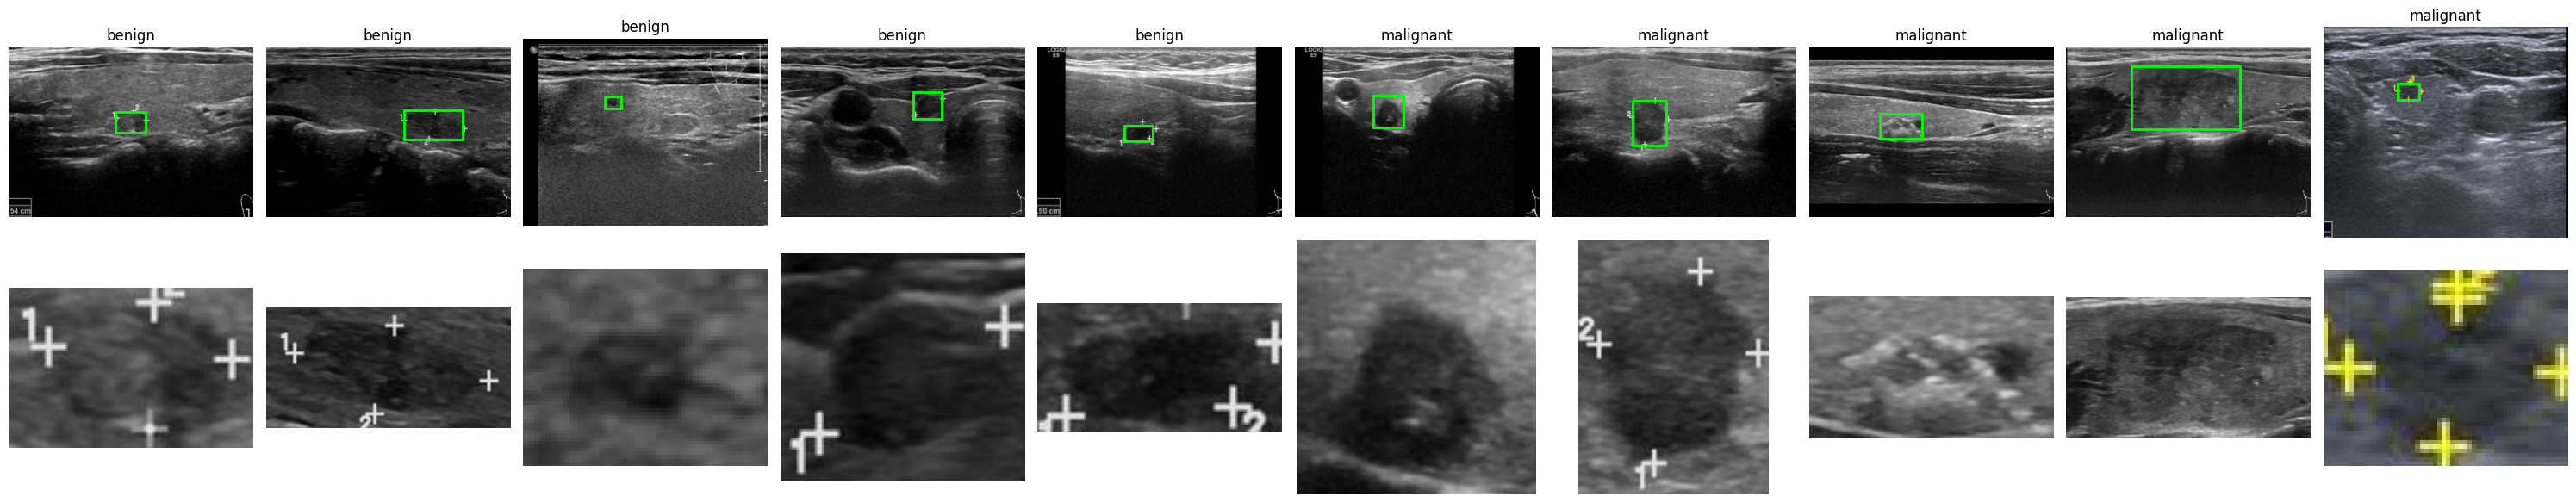

In [10]:
#cell 3: import matplotlib.pyplot as plt
ds = ROIDataset(df, lambda x: x)
rng = np.random.RandomState(0)
pick = list(rng.choice(df.index[df.label == 0], 5, replace=False)) + list(rng.choice(df.index[df.label == 1], 5, replace=False))
fig, ax = plt.subplots(2, 10, figsize=(30, 6))
for k, i in enumerate(pick):
    r = df.loc[i]; full = Image.open(r.path).convert('RGB')
    ax[0, k].imshow(full); ax[0, k].add_patch(plt.Rectangle((r.x1, r.y1), r.x2-r.x1, r.y2-r.y1, fill=False, ec='lime', lw=2))
    ax[0, k].set_title('malignant' if r.label else 'benign'); ax[0, k].axis('off')
    ax[1, k].imshow(ds.get_pil(i)); ax[1, k].axis('off')
plt.tight_layout(); plt.show()

In [12]:
#This tests whether calipers or color are associated with the class. Run it after Cell 3:
from sklearn.metrics import roc_auc_score
ds = ROIDataset(df, lambda x: x)

def crop_stats(i):
    a = np.asarray(ds.get_pil(i)).astype(np.float32)               # H, W, 3
    color  = np.abs(a[..., 0] - a[..., 1]).mean() + np.abs(a[..., 1] - a[..., 2]).mean()
    bright = (a.mean(2) >= 240).mean()                             # near-white pixels (calipers, text)
    return color, bright, a.shape[0] * a.shape[1]

df[['color', 'bright', 'crop_area']] = np.array([crop_stats(i) for i in df.index])
df['is_color'] = df.color > 2                                      # grayscale images give ~0

print(df.groupby('label')[['color', 'bright', 'crop_area']].median().round(3))
print('\ncolored-image rate by class:'); print(df.groupby('label').is_color.mean().round(3))
print('\ncolored-image rate by split:'); print(df.assign(split=df.index.map(split_of)).groupby('split').is_color.mean().round(3))
for c in ['color', 'bright', 'crop_area']:
    print(f'single-feature AUC for malignant ({c}): {roc_auc_score(df.label, df[c]):.3f}')
    print((df.bright > 0).groupby(df.label).mean().round(3))

       color  bright  crop_area
label                          
0        0.0     0.0    10498.0
1        0.0     0.0    23628.5

colored-image rate by class:
label
0    0.055
1    0.038
Name: is_color, dtype: float64

colored-image rate by split:
split
test     0.036
train    0.046
val      0.038
Name: is_color, dtype: float64
single-feature AUC for malignant (color): 0.492
label
0    0.358
1    0.375
Name: bright, dtype: float64
single-feature AUC for malignant (bright): 0.501
label
0    0.358
1    0.375
Name: bright, dtype: float64
single-feature AUC for malignant (crop_area): 0.679
label
0    0.358
1    0.375
Name: bright, dtype: float64


#feature extraction

In [13]:
#Cell 4:
@torch.no_grad()
def extract(name, tag, bs=64):
    f = FEAT_DIR / f'{name}_{"roi" if USE_ROI else "full"}.npy'
    meta = FEAT_DIR / f'{name}_time.json'
    if f.exists(): return np.load(f)
    t0 = time.time()
    m = timm.create_model(tag, pretrained=True, num_classes=0).to(device).eval()   # classifier removed -> pooled vector
    feats = []
    for x, _ in loader(df.index.values, eval_tfm(m), bs=bs):                        # df order == row order
        with torch.autocast(device, enabled=(device == 'cuda')):
            feats.append(m(x.to(device)).float().cpu().numpy())
    feats = np.concatenate(feats)
    np.save(f, feats); json.dump({'extract_s': time.time() - t0, 'dim': int(feats.shape[1])}, open(meta, 'w'))
    del m; torch.cuda.empty_cache()
    return feats

FEATS = {}
for n, t in BACKBONES.items():
    FEATS[n] = extract(n, t)
    print(f'{n:15s} features {FEATS[n].shape}  NaN={np.isnan(FEATS[n]).any()}')

model.safetensors: reconstructing file:   0%|          |  0.00B / 32.3MB            

model.safetensors: downloading bytes:           |  0.00B            

DenseNet121     features (5000, 1024)  NaN=False


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

...

model.safetensors: downloading bytes:           |  0.00B            

InceptionV3     features (5000, 2048)  NaN=False
Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
Xception        features (5000, 2048)  NaN=False


model.safetensors: reconstructing file:   0%|          |  0.00B / 78.1MB            

model.safetensors: downloading bytes:           |  0.00B            

RegNetY032      features (5000, 1512)  NaN=False


#Classifiers(class-weighted)

In [14]:
#Cell 5:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

def make_models(seed=SEED):
    sc = lambda: StandardScaler()          # fitted on TRAIN only (pipeline is fit on train features)
    return {
        'SVM':          make_pipeline(sc(), PCA(0.99, random_state=seed), SVC(C=1, kernel='rbf', class_weight='balanced')),
        'RandomForest': RandomForestClassifier(500, class_weight='balanced', n_jobs=-1, random_state=seed),
        'XGBoost':      XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8,
                                      colsample_bytree=0.5, scale_pos_weight=spw, tree_method='hist', device=device,
                                      eval_metric='logloss', random_state=seed),
        'LogReg':       make_pipeline(sc(), LogisticRegression(C=0.1, max_iter=3000, class_weight='balanced')),
        'ExtraTrees':   ExtraTreesClassifier(500, class_weight='balanced', n_jobs=-1, random_state=seed),
        'KNN':          make_pipeline(sc(), PCA(0.99, random_state=seed), KNeighborsClassifier(n_neighbors=15, weights='distance')),
        'LightGBM':     LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, colsample_bytree=0.5,
                                       subsample=0.8, subsample_freq=1, class_weight='balanced',
                                       random_state=seed, verbose=-1),
    }

def get_score(model, X):
    """Continuous malignant score + default threshold (SVM has no probabilities -> margin, thr 0)."""
    if hasattr(model, 'predict_proba'): return model.predict_proba(X)[:, 1], 0.5
    return model.decision_function(X), 0.0

In [15]:
#Cell 6: running all 49 combinations
def run_backbone(bname):
    f_csv, f_pkl = RES_DIR / f'a2_{bname}.csv', RES_DIR / f'a2_scores_{bname}.pkl'
    if f_csv.exists() and f_pkl.exists():
        print('skip (done):', bname); return pd.read_csv(f_csv)
    X, rows, scores = FEATS[bname], [], {}
    for mname, model in make_models(SEED).items():
        t0 = time.time(); model.fit(X[tr], y[tr]); fit_s = time.time() - t0
        s_va, thr0 = get_score(model, X[va]); s_te, _ = get_score(model, X[te])
        scores[mname] = dict(s_va=s_va, s_te=s_te, thr0=thr0)
        rows += report('2_deepfeat_ML', bname, mname, s_va, s_te, thr0, train_s=fit_s, feat_dim=X.shape[1])
        print(f'{bname:15s} {mname:13s} val_AUC={rows[-1]["Val_AUC"]:.3f}  test_AUC={rows[-1]["ROC_AUC"]:.3f}  fit={fit_s:.0f}s')
    pickle.dump(scores, open(f_pkl, 'wb')); out = pd.DataFrame(rows); out.to_csv(f_csv, index=False)
    return out

res2 = pd.concat([run_backbone(b) for b in BACKBONES], ignore_index=True)
res2.to_csv(RES_DIR / 'approach2_all.csv', index=False)
print(res2.shape)

DenseNet121     SVM           val_AUC=0.948  test_AUC=0.908  fit=4s
DenseNet121     RandomForest  val_AUC=0.927  test_AUC=0.893  fit=51s


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [04:36:26] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


DenseNet121     XGBoost       val_AUC=0.938  test_AUC=0.903  fit=3s
DenseNet121     LogReg        val_AUC=0.904  test_AUC=0.873  fit=1s
DenseNet121     ExtraTrees    val_AUC=0.931  test_AUC=0.885  fit=8s
DenseNet121     KNN           val_AUC=0.917  test_AUC=0.867  fit=1s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


DenseNet121     LightGBM      val_AUC=0.945  test_AUC=0.903  fit=27s
ResNet50        SVM           val_AUC=0.945  test_AUC=0.896  fit=8s
ResNet50        RandomForest  val_AUC=0.924  test_AUC=0.876  fit=67s
ResNet50        XGBoost       val_AUC=0.949  test_AUC=0.896  fit=5s
ResNet50        LogReg        val_AUC=0.919  test_AUC=0.883  fit=2s
ResNet50        ExtraTrees    val_AUC=0.926  test_AUC=0.873  fit=10s
ResNet50        KNN           val_AUC=0.887  test_AUC=0.848  fit=5s


...

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


InceptionV3     LightGBM      val_AUC=0.930  test_AUC=0.893  fit=51s
Xception        SVM           val_AUC=0.926  test_AUC=0.886  fit=10s
Xception        RandomForest  val_AUC=0.905  test_AUC=0.863  fit=44s
Xception        XGBoost       val_AUC=0.926  test_AUC=0.882  fit=5s
Xception        LogReg        val_AUC=0.879  test_AUC=0.851  fit=1s
Xception        ExtraTrees    val_AUC=0.904  test_AUC=0.865  fit=10s
Xception        KNN           val_AUC=0.884  test_AUC=0.851  fit=5s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Xception        LightGBM      val_AUC=0.924  test_AUC=0.885  fit=54s
RegNetY032      SVM           val_AUC=0.899  test_AUC=0.865  fit=7s
RegNetY032      RandomForest  val_AUC=0.887  test_AUC=0.849  fit=36s
RegNetY032      XGBoost       val_AUC=0.900  test_AUC=0.873  fit=3s
RegNetY032      LogReg        val_AUC=0.837  test_AUC=0.823  fit=1s
RegNetY032      ExtraTrees    val_AUC=0.875  test_AUC=0.844  fit=10s
RegNetY032      KNN           val_AUC=0.836  test_AUC=0.809  fit=2s
RegNetY032      LightGBM      val_AUC=0.901  test_AUC=0.872  fit=39s
(98, 21)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


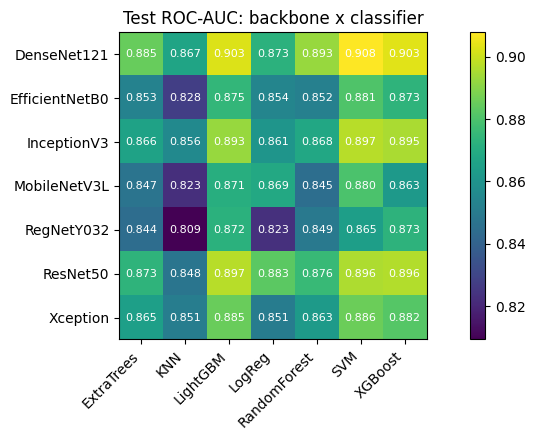

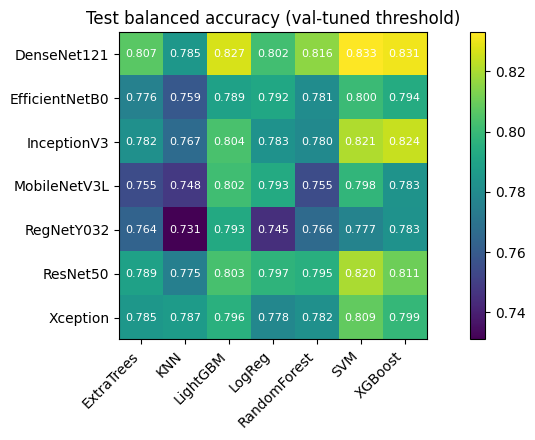

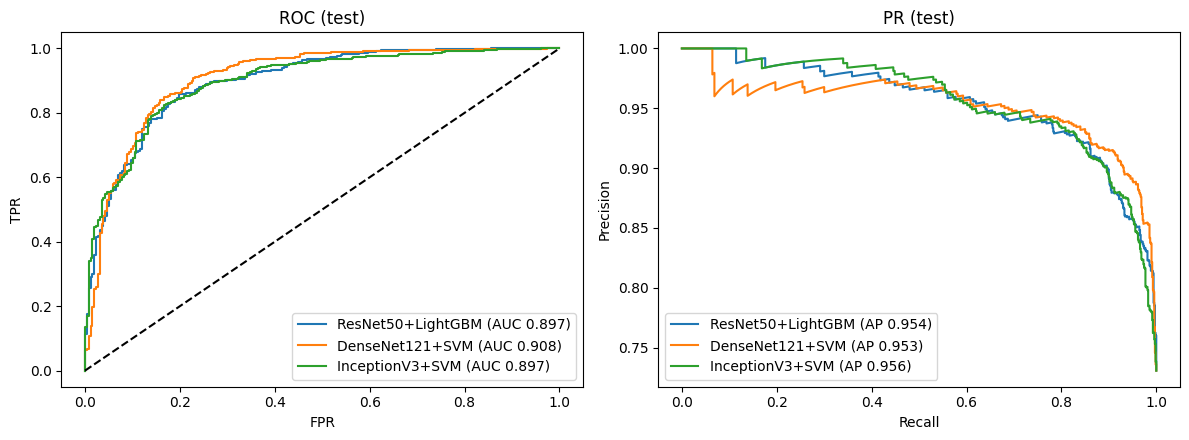

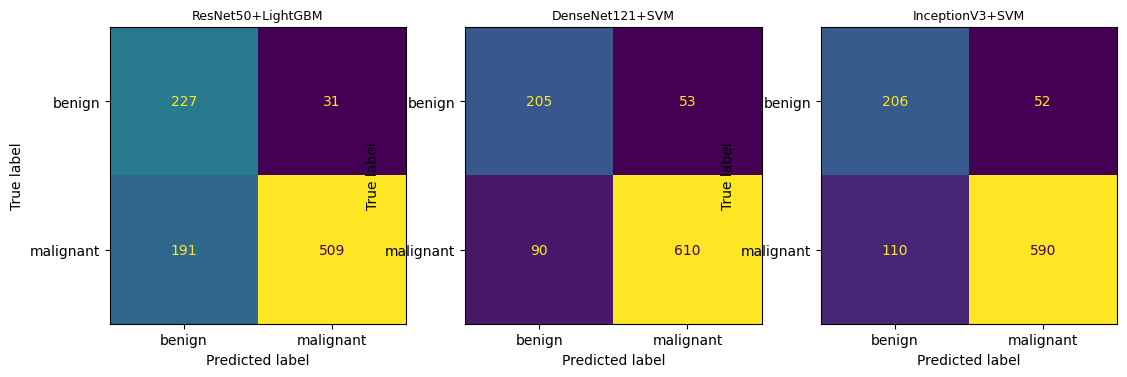

saved to /content/drive/MyDrive/TN5000_results/experiment2_final
['all_results.csv', 'auc_grid_tuned.csv', 'balacc_grid_tuned.csv', 'best_default.csv', 'best_tuned.csv', 'confusion_top3.pdf', 'confusion_top3.png', 'cost.csv', 'experiment2_results.xlsx', 'heatmap_auc.pdf', 'heatmap_auc.png', 'heatmap_balacc.pdf', 'heatmap_balacc.png', 'mean_by_backbone.csv', 'mean_by_classifier.csv', 'roc_pr_top3.pdf', 'roc_pr_top3.png', 'run_metadata.json', 'top_errors.csv']


In [17]:
#Cell 8: downloading all files: Save all tables, figures and run metadata(but run after cell 6)
import json, pickle, platform, shutil, sklearn, xgboost, lightgbm
import matplotlib, matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, roc_curve, confusion_matrix

OUT = RES_DIR / 'experiment2_final'
(OUT / 'figures').mkdir(parents=True, exist_ok=True); (OUT / 'tables').mkdir(exist_ok=True)

# ---- 0) use the cleaned splits and the full results table ----
S = np.load(RES_DIR / 'splits_clean.npz'); tr, va, te = S['tr'], S['va'], S['te']
res2 = pd.read_csv(RES_DIR / 'approach2_all.csv')
cols = ['Acc','BalAcc','MacroF1','BenignRecall','MalignantRecall','MalignantPrecision','ROC_AUC','PR_AUC']
tuned, default = res2[res2.threshold == 'val_tuned_thr'], res2[res2.threshold == 'default_thr']

# ---- 1) tables ----
best = tuned.loc[tuned.groupby('backbone')['Val_AUC'].idxmax()].sort_values('Val_AUC', ascending=False)  # chosen on VAL
keys = list(zip(best.backbone, best.learner))
best_def = default.set_index(['backbone', 'learner']).loc[keys].reset_index()
grid_auc = tuned.pivot(index='backbone', columns='learner', values='ROC_AUC')
grid_bal = tuned.pivot(index='backbone', columns='learner', values='BalAcc')
mean_bb  = tuned.groupby('backbone')[cols].mean()
mean_clf = tuned.groupby('learner')[cols].mean()

meta = {b: json.load(open(FEAT_DIR / f'{b}_time.json')) for b in BACKBONES if (FEAT_DIR / f'{b}_time.json').exists()}
cost = pd.DataFrame({'feat_dim': {b: m['dim'] for b, m in meta.items()},
                     'extract_s': {b: round(m['extract_s']) for b, m in meta.items()},
                     'mean_fit_s': tuned.groupby('backbone').train_s.mean().round(1)})

wrong = np.zeros(len(te))                                       # most-misclassified test images
for _, r in best.iterrows():
    sc = pickle.load(open(RES_DIR / f'a2_scores_{r.backbone}.pkl', 'rb'))[r.learner]
    assert len(sc['s_te']) == len(te), 'saved scores do not match current test split'
    wrong += ((sc['s_te'] >= r.thr_value).astype(int) != y[te])
err = df.loc[te, ['path', 'label']].assign(n_backbones_wrong=wrong).sort_values('n_backbones_wrong', ascending=False)

tables = {'all_results': res2, 'best_tuned': best, 'best_default': best_def,
          'auc_grid_tuned': grid_auc.reset_index(), 'balacc_grid_tuned': grid_bal.reset_index(),
          'mean_by_backbone': mean_bb.reset_index(), 'mean_by_classifier': mean_clf.reset_index(),
          'cost': cost.reset_index(), 'top_errors': err.head(50)}
for name, t in tables.items():
    t.to_csv(OUT / 'tables' / f'{name}.csv', index=False)
with pd.ExcelWriter(OUT / 'experiment2_results.xlsx') as xw:      # one workbook, one sheet per table
    for name, t in tables.items():
        t.round(4).to_excel(xw, sheet_name=name[:31], index=False)

# ---- 2) figures (saved BEFORE show, as PNG at 300 dpi and PDF) ----
def save(fig, name):
    fig.savefig(OUT / 'figures' / f'{name}.png', dpi=300, bbox_inches='tight')
    fig.savefig(OUT / 'figures' / f'{name}.pdf', bbox_inches='tight'); plt.show()

def heatmap(g, title, name):
    fig, ax = plt.subplots(figsize=(9, 4.5)); im = ax.imshow(g.values, cmap='viridis')
    ax.set_xticks(range(g.shape[1]), g.columns, rotation=45, ha='right'); ax.set_yticks(range(g.shape[0]), g.index)
    for i in range(g.shape[0]):
        for j in range(g.shape[1]): ax.text(j, i, f'{g.values[i,j]:.3f}', ha='center', va='center', color='w', fontsize=8)
    plt.colorbar(im); ax.set_title(title); plt.tight_layout(); save(fig, name)

heatmap(grid_auc, 'Test ROC-AUC: backbone x classifier', 'heatmap_auc')
heatmap(grid_bal, 'Test balanced accuracy (val-tuned threshold)', 'heatmap_balacc')

top = best.head(3)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5)); fig2, ax2 = plt.subplots(1, 3, figsize=(13, 4))
for k, (_, r) in enumerate(top.iterrows()):
    sc = pickle.load(open(RES_DIR / f'a2_scores_{r.backbone}.pkl', 'rb'))[r.learner]
    fpr, tpr, _ = roc_curve(y[te], sc['s_te']); pr, rc, _ = precision_recall_curve(y[te], sc['s_te'])
    lab = f'{r.backbone}+{r.learner}'
    ax[0].plot(fpr, tpr, label=f'{lab} (AUC {r.ROC_AUC:.3f})'); ax[1].plot(rc, pr, label=f'{lab} (AP {r.PR_AUC:.3f})')
    ConfusionMatrixDisplay(confusion_matrix(y[te], (sc['s_te'] >= r.thr_value).astype(int)),
                           display_labels=['benign', 'malignant']).plot(ax=ax2[k], colorbar=False); ax2[k].set_title(lab, fontsize=9)
ax[0].plot([0, 1], [0, 1], 'k--'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend(); ax[0].set_title('ROC (test)')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend(); ax[1].set_title('PR (test)')
fig.tight_layout(); save(fig, 'roc_pr_top3'); fig2.tight_layout(); save(fig2, 'confusion_top3')

# ---- 3) run metadata for reproducibility ----
json.dump({
    'seed': SEED, 'roi': USE_ROI, 'roi_margin': ROI_MARGIN, 'backbones': BACKBONES,
    'split_sizes': {'train': len(tr), 'val_clean': len(va), 'test_clean': len(te),
                    'val_official': int(len(S['va_full'])), 'test_official': int(len(S['te_full']))},
    'class_counts': {n: np.bincount(y[i]).tolist() for n, i in [('train', tr), ('val', va), ('test', te)]},
    'xgboost_scale_pos_weight': float(spw),
    'classifiers': {k: str(v) for k, v in make_models(SEED).items()},
    'threshold_rule': 'max balanced accuracy on validation; default = 0.5 (SVM: 0)',
    'selection_rule': 'best classifier per backbone by validation ROC-AUC',
    'versions': {'python': platform.python_version(), 'torch': torch.__version__, 'timm': timm.__version__,
                 'sklearn': sklearn.__version__, 'xgboost': xgboost.__version__, 'lightgbm': lightgbm.__version__}
}, open(OUT / 'run_metadata.json', 'w'), indent=2)

print('saved to', OUT); print(sorted(p.name for p in OUT.rglob('*') if p.is_file()))

# ---- 4) optional: download everything as one zip to your computer ----
# from google.colab import files
# files.download(shutil.make_archive('/content/experiment2_final', 'zip', OUT))

#selection and analysis

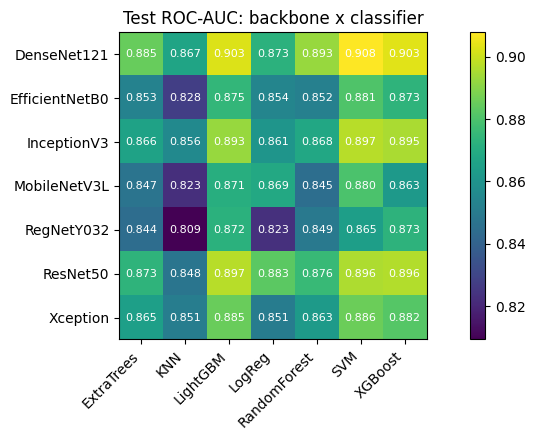

                  Acc  BalAcc  MacroF1  BenignRecall  MalignantRecall  \
backbone                                                                
DenseNet121     0.825   0.814    0.792         0.791            0.838   
EfficientNetB0  0.781   0.784    0.749         0.791            0.778   
InceptionV3     0.793   0.794    0.761         0.797            0.791   
MobileNetV3L    0.770   0.776    0.739         0.791            0.762   
RegNetY032      0.768   0.766    0.733         0.761            0.770   
ResNet50        0.804   0.799    0.771         0.787            0.811   
Xception        0.802   0.791    0.767         0.767            0.815   

                MalignantPrecision  ROC_AUC  PR_AUC  
backbone                                             
DenseNet121                  0.916    0.890   0.945  
EfficientNetB0               0.911    0.859   0.929  
InceptionV3                  0.914    0.877   0.943  
MobileNetV3L                 0.908    0.857   0.928  
RegNetY032        

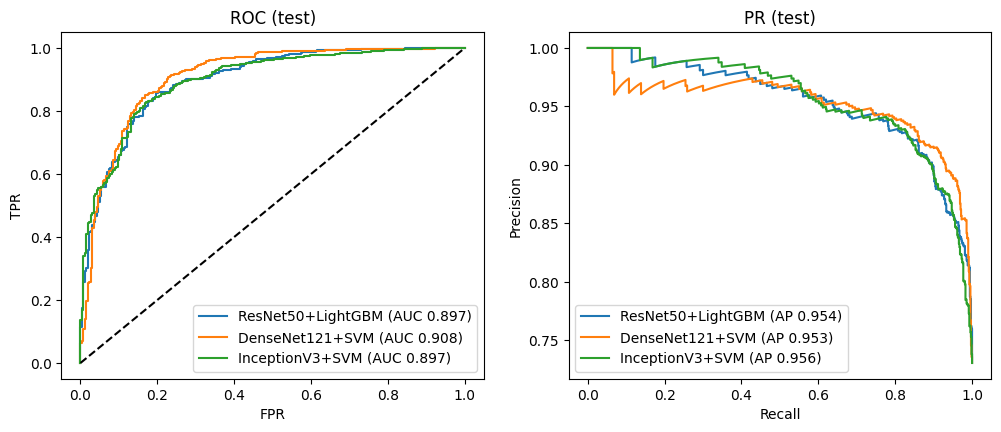

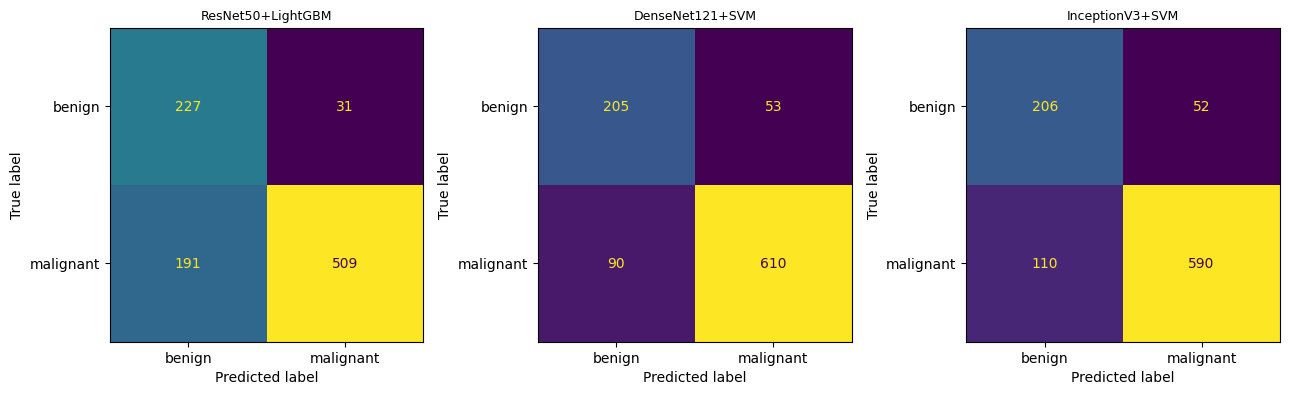

                feat_dim  extract_s  mean_fit_s
DenseNet121         1024         28        13.4
EfficientNetB0      1280         23        15.2
InceptionV3         2048         35        20.8
MobileNetV3L        1280         25        14.8
RegNetY032          1512         24        14.1
ResNet50            2048         23        21.3
Xception            2048         35        18.3
                                                  path  label  n_backbones_wrong
/content/TN5000/TN5000_forReview/JPEGImages/000131.jpg      0                7.0
/content/TN5000/TN5000_forReview/JPEGImages/000115.jpg      1                7.0
/content/TN5000/TN5000_forReview/JPEGImages/000009.jpg      0                7.0
/content/TN5000/TN5000_forReview/JPEGImages/001965.jpg      1                7.0
/content/TN5000/TN5000_forReview/JPEGImages/000048.jpg      0                7.0
/content/TN5000/TN5000_forReview/JPEGImages/000174.jpg      0                7.0
/content/TN5000/TN5000_forReview/JPEGImages/00037

In [16]:
#cell 7:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve

cols = ['Acc','BalAcc','MacroF1','BenignRecall','MalignantRecall','MalignantPrecision','ROC_AUC','PR_AUC']
tuned = res2[res2.threshold == 'val_tuned_thr']

# 1) backbone x classifier grid (ROC-AUC) --------------------------------------------------
grid = tuned.pivot(index='backbone', columns='learner', values='ROC_AUC')
fig, ax = plt.subplots(figsize=(9, 4.5)); im = ax.imshow(grid.values, cmap='viridis')
ax.set_xticks(range(grid.shape[1]), grid.columns, rotation=45, ha='right'); ax.set_yticks(range(grid.shape[0]), grid.index)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]): ax.text(j, i, f'{grid.values[i,j]:.3f}', ha='center', va='center', color='w', fontsize=8)
plt.colorbar(im); plt.title('Test ROC-AUC: backbone x classifier'); plt.tight_layout(); plt.show()

# 2) averages by backbone and by classifier ------------------------------------------------
print(tuned.groupby('backbone')[cols].mean().round(3), '\n')
print(tuned.groupby('learner')[cols].mean().round(3), '\n')

# 3) best classifier per backbone, chosen by VALIDATION ROC-AUC (no test peeking) -----------
idx = tuned.groupby('backbone')['Val_AUC'].idxmax()
best = tuned.loc[idx].sort_values('Val_AUC', ascending=False)
best_def = res2[(res2.threshold == 'default_thr')].set_index(['backbone', 'learner']).loc[list(zip(best.backbone, best.learner))].reset_index()
print('--- val-tuned threshold ---'); print(best[['backbone','learner','Val_AUC'] + cols].round(3).to_string(index=False))
print('--- default threshold ---');   print(best_def[['backbone','learner'] + cols].round(3).to_string(index=False))
best.to_csv(RES_DIR / 'approach2_best_per_backbone.csv', index=False)

# 4) ROC / PR curves + confusion matrices for the top 3 (by val AUC) ------------------------
top = best.head(3)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5)); fig2, ax2 = plt.subplots(1, 3, figsize=(13, 4))
for k, (_, r) in enumerate(top.iterrows()):
    sc = pickle.load(open(RES_DIR / f'a2_scores_{r.backbone}.pkl', 'rb'))[r.learner]
    fpr, tpr, _ = roc_curve(y[te], sc['s_te']); pr, rc, _ = precision_recall_curve(y[te], sc['s_te'])
    lab = f'{r.backbone}+{r.learner}'
    ax[0].plot(fpr, tpr, label=f'{lab} (AUC {r.ROC_AUC:.3f})'); ax[1].plot(rc, pr, label=f'{lab} (AP {r.PR_AUC:.3f})')
    ConfusionMatrixDisplay(confusion_matrix(y[te], (sc['s_te'] >= r.thr_value).astype(int)),
                           display_labels=['benign', 'malignant']).plot(ax=ax2[k], colorbar=False); ax2[k].set_title(lab, fontsize=9)
ax[0].plot([0, 1], [0, 1], 'k--'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend(); ax[0].set_title('ROC (test)')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend(); ax[1].set_title('PR (test)')
plt.tight_layout(); plt.show()

# 5) cost table -----------------------------------------------------------------------------
meta = {b: json.load(open(FEAT_DIR / f'{b}_time.json')) for b in BACKBONES if (FEAT_DIR / f'{b}_time.json').exists()}
cost = pd.DataFrame({'feat_dim': {b: m['dim'] for b, m in meta.items()},
                     'extract_s': {b: round(m['extract_s']) for b, m in meta.items()},
                     'mean_fit_s': tuned.groupby('backbone').train_s.mean().round(1)})
print(cost)

# 6) error analysis: test images misclassified by most backbones (best classifier each, tuned thr) ----
wrong = np.zeros(len(te))
for _, r in best.iterrows():
    sc = pickle.load(open(RES_DIR / f'a2_scores_{r.backbone}.pkl', 'rb'))[r.learner]
    wrong += ((sc['s_te'] >= r.thr_value).astype(int) != y[te])
err = df.loc[te].assign(n_backbones_wrong=wrong).sort_values('n_backbones_wrong', ascending=False)
print(err[['path', 'label', 'n_backbones_wrong']].head(20).to_string(index=False))